# Checkpoint 1 · Notebook 02: Classification & Regression Baselines + Leakage Ablation

**Project 7 — Repurposing Approved Drugs Against `AChE` (Acetylcholinesterase, `CHEMBL220`)**

In this notebook we establish our **Checkpoint 1 baseline numbers** under both ligand-based formulations:
1. **Binary Classification** (`pIC50 >= 6.0` active vs `<= 5.0` inactive + rescued `> 10 uM` censored inactives):
   - **Max Tanimoto similarity (ECFP4)** to training actives (classic similarity baseline)
   - **Logistic Regression (ECFP4)** (linear baseline)
   - **Random Forest Classifier (ECFP4 + RDKit descriptors)**
2. **Continuous `pIC50` Regression** (exact `=` IC50 records, reusing Assignment 5 Part 2/3):
   - **Random Forest Regressor (ECFP4)**
   - **Random Forest Regressor (RDKit descriptors)**
   - **Random Forest Regressor (ECFP4 + RDKit descriptors)**
3. **Controls & Ablations:**
   - **Random split vs. Bemis–Murcko scaffold split** (`scaffold_split`, Assignment 5 Task B)
   - **Trivial size control:** `MolWt` alone (Assignment 5 Q3b)
   - **3-tier leakage ablation** on the approved-drug ranking:
     - *Naive (leaky)* vs *Exact leak-free* vs *Strict analogue-free (`Tanimoto < 0.85`)*
   - **Applicability Domain:** max ECFP4 Tanimoto similarity of each approved drug to training actives.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from bioinfo_repurposing.baselines import (
    evaluate_internal_classification,
    evaluate_internal_regression,
    rank_approved_drugs_suite,
)
from bioinfo_repurposing.features import ecfp4_bitvects, max_tanimoto_similarity

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path("..").resolve()
PROC_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "AChE"
TARGET_LOW = TARGET.lower()
SEEDS = (0, 1, 2, 3, 4)

approved_df = pd.read_csv(PROC_DIR / f"{TARGET_LOW}_approved_library.csv")
df_clf_naive = pd.read_csv(PROC_DIR / f"{TARGET_LOW}_clf_naive.csv", index_col=0)
df_clf_clean = pd.read_csv(PROC_DIR / f"{TARGET_LOW}_clf_leakfree.csv", index_col=0)
df_clf_strict = pd.read_csv(PROC_DIR / f"{TARGET_LOW}_clf_strict.csv", index_col=0)

df_reg_naive = pd.read_csv(PROC_DIR / f"{TARGET_LOW}_reg_naive.csv", index_col=0)
df_reg_clean = pd.read_csv(PROC_DIR / f"{TARGET_LOW}_reg_leakfree.csv", index_col=0)
df_reg_strict = pd.read_csv(PROC_DIR / f"{TARGET_LOW}_reg_strict.csv", index_col=0)

print(f"Approved library: {len(approved_df):,} drugs ({approved_df['is_positive_control'].sum()} positive controls)")
print(f"Leak-free classification set: {len(df_clf_clean):,} | Leak-free regression set: {len(df_reg_clean):,}")


Approved library: 2,027 drugs (18 positive controls)
Leak-free classification set: 4,338 | Leak-free regression set: 5,613


## 1. Internal Held-Out Validation: Random Split vs. Bemis–Murcko Scaffold Split

Evaluated on the **exact leak-free** ChEMBL datasets across 5 random seeds (mean ± std).


In [2]:
internal_clf = evaluate_internal_classification(df_clf_clean, seeds=SEEDS, test_fraction=0.25)
internal_reg = evaluate_internal_regression(df_reg_clean, seeds=SEEDS, test_fraction=0.25)

print("=== Internal Classification (Random vs Bemis-Murcko Scaffold Split) ===")
display(internal_clf.round(3))

print("\n=== Internal pIC50 Regression (Random vs Bemis-Murcko Scaffold Split) ===")
display(internal_reg.round(3))

internal_clf.to_csv(PROC_DIR / f"{TARGET_LOW}_internal_clf_metrics.csv", index=False)
internal_reg.to_csv(PROC_DIR / f"{TARGET_LOW}_internal_reg_metrics.csv", index=False)


=== Internal Classification (Random vs Bemis-Murcko Scaffold Split) ===


,task,model,split,ROC_AUC_mean,ROC_AUC_std,PR_AUC_mean,PR_AUC_std
0,classification,Max Tanimoto (ECFP4),random,0.900,0.008,0.926,0.006
1,classification,Logistic Regression (ECFP4),random,0.935,0.004,0.955,0.005
2,classification,RF Classifier (ECFP4+Desc),random,0.960,0.006,0.974,0.006
3,classification,Max Tanimoto (ECFP4),scaffold,0.844,0.000,0.895,0.000
4,classification,Logistic Regression (ECFP4),scaffold,0.862,0.000,0.909,0.000
5,classification,RF Classifier (ECFP4+Desc),scaffold,0.900,0.002,0.938,0.002



=== Internal pIC50 Regression (Random vs Bemis-Murcko Scaffold Split) ===


,task,model,split,R2_mean,R2_std,MAE_mean,MAE_std
0,regression,RF Regressor (ECFP4),random,0.705,0.020,0.511,0.018
1,regression,RF Regressor (RDKit Desc),random,0.526,0.011,0.672,0.012
2,regression,RF Regressor (ECFP4+Desc),random,0.713,0.020,0.507,0.019
3,regression,RF Regressor (ECFP4),scaffold,0.462,0.002,0.777,0.002
4,regression,RF Regressor (RDKit Desc),scaffold,0.275,0.003,0.914,0.001
5,regression,RF Regressor (ECFP4+Desc),scaffold,0.488,0.003,0.762,0.002


## 2. Approved-Drug Ranking & 3-Tier Leakage Ablation

We rank the entire curated approved small-molecule library and measure recovery of the known `{target_symbol}` approved drugs (`ROC_AUC`, `PR_AUC`, `EF@1%`, `EF@5%`, `BEDROC20`, median rank, and % in top 1% / top 5%) across all three leakage tiers:
1. **Naive (leaky)**: approved drugs remain in ChEMBL training.
2. **Leak-free (exact)**: all approved drugs removed from training by parent `InChIKey14` / canonical SMILES.
3. **Strict (analogue-free)**: exact approved drugs **plus** any training molecule with ECFP4 `Tanimoto >= 0.85` to an approved drug removed.


In [3]:
res_naive, scores_naive = rank_approved_drugs_suite(df_clf_naive, df_reg_naive, approved_df, "1_Naive_Leaky", seeds=SEEDS)
res_clean, scores_clean = rank_approved_drugs_suite(df_clf_clean, df_reg_clean, approved_df, "2_LeakFree_Exact", seeds=SEEDS)
res_strict, scores_strict = rank_approved_drugs_suite(df_clf_strict, df_reg_strict, approved_df, "3_Strict_Tanimoto<0.85", seeds=SEEDS)

all_rank_res = pd.concat([res_naive, res_clean, res_strict], ignore_index=True)
all_rank_res.to_csv(PROC_DIR / f"{TARGET_LOW}_approved_ranking_metrics.csv", index=False)

cols_show = [
    "leakage_tier",
    "formulation",
    "method",
    "ROC_AUC_mean",
    "PR_AUC_mean",
    "EF@1%_mean",
    "EF@5%_mean",
    "BEDROC20_mean",
    "median_rank_mean",
    "pct_in_top5_mean",
]
print("=== Main Checkpoint 1 Result: Leak-Free (Exact) Approved-Drug Ranking ===")
display(res_clean[cols_show].round(3))

print("\n=== Full 3-Tier Leakage Ablation ===")
display(all_rank_res[cols_show].round(3))


=== Main Checkpoint 1 Result: Leak-Free (Exact) Approved-Drug Ranking ===


,leakage_tier,formulation,method,ROC_AUC_mean,PR_AUC_mean,EF@1%_mean,EF@5%_mean,BEDROC20_mean,median_rank_mean,pct_in_top5_mean
0,2_LeakFree_Exact,control,Control: MolWt alone,0.378,0.007,0.000,0.000,0.018,1440.0,0.000
1,2_LeakFree_Exact,classification,Max Tanimoto (ECFP4),0.847,0.467,48.262,13.248,0.654,21.0,66.667
2,2_LeakFree_Exact,classification,Logistic Regression (ECFP4),0.654,0.021,5.362,3.312,0.149,635.0,16.667
3,2_LeakFree_Exact,classification,RF Classifier (ECFP4+Desc),0.631,0.247,27.885,9.274,0.426,154.5,46.667
4,2_LeakFree_Exact,regression,RF Regressor (ECFP4),0.540,0.133,16.087,3.533,0.198,812.8,17.778
5,2_LeakFree_Exact,regression,RF Regressor (RDKit Desc),0.589,0.032,5.362,4.416,0.178,700.2,22.222
6,2_LeakFree_Exact,regression,RF Regressor (ECFP4+Desc),0.613,0.200,19.305,7.066,0.322,522.9,35.556



=== Full 3-Tier Leakage Ablation ===


,leakage_tier,formulation,method,ROC_AUC_mean,PR_AUC_mean,EF@1%_mean,EF@5%_mean,BEDROC20_mean,median_rank_mean,pct_in_top5_mean
0,1_Naive_Leaky,control,Control: MolWt alone,0.378,0.007,0.000,0.000,0.018,1440.0,0.000
1,1_Naive_Leaky,classification,Max Tanimoto (ECFP4),0.901,0.305,48.262,15.456,0.723,22.5,77.778
2,1_Naive_Leaky,classification,Logistic Regression (ECFP4),0.665,0.023,5.362,3.312,0.155,521.5,16.667
3,1_Naive_Leaky,classification,RF Classifier (ECFP4+Desc),0.700,0.325,36.465,11.482,0.546,50.7,57.778
4,1_Naive_Leaky,regression,RF Regressor (ECFP4),0.616,0.159,20.377,6.624,0.306,694.9,33.333
5,1_Naive_Leaky,regression,RF Regressor (RDKit Desc),0.585,0.040,10.725,4.858,0.203,772.9,24.444
6,1_Naive_Leaky,regression,RF Regressor (ECFP4+Desc),0.658,0.204,22.522,8.611,0.392,368.5,43.333
7,2_LeakFree_Exact,control,Control: MolWt alone,0.378,0.007,0.000,0.000,0.018,1440.0,0.000
8,2_LeakFree_Exact,classification,Max Tanimoto (ECFP4),0.847,0.467,48.262,13.248,0.654,21.0,66.667
9,2_LeakFree_Exact,classification,Logistic Regression (ECFP4),0.654,0.021,5.362,3.312,0.149,635.0,16.667


## 3. Enrichment Curves, Leakage Inflation Plot & Top Ranked Approved Drugs

We visualize (a) how much **data leakage inflates** `EF@5%` and `BEDROC20` across the three tiers, (b) cumulative enrichment curves for the leak-free baselines vs. `MolWt` control and random chance, and (c) inspect both the **recovered positive controls** and the **top non-approved repurposing candidates** alongside their **Applicability Domain** (`AD_max_tanimoto` to leak-free training actives).


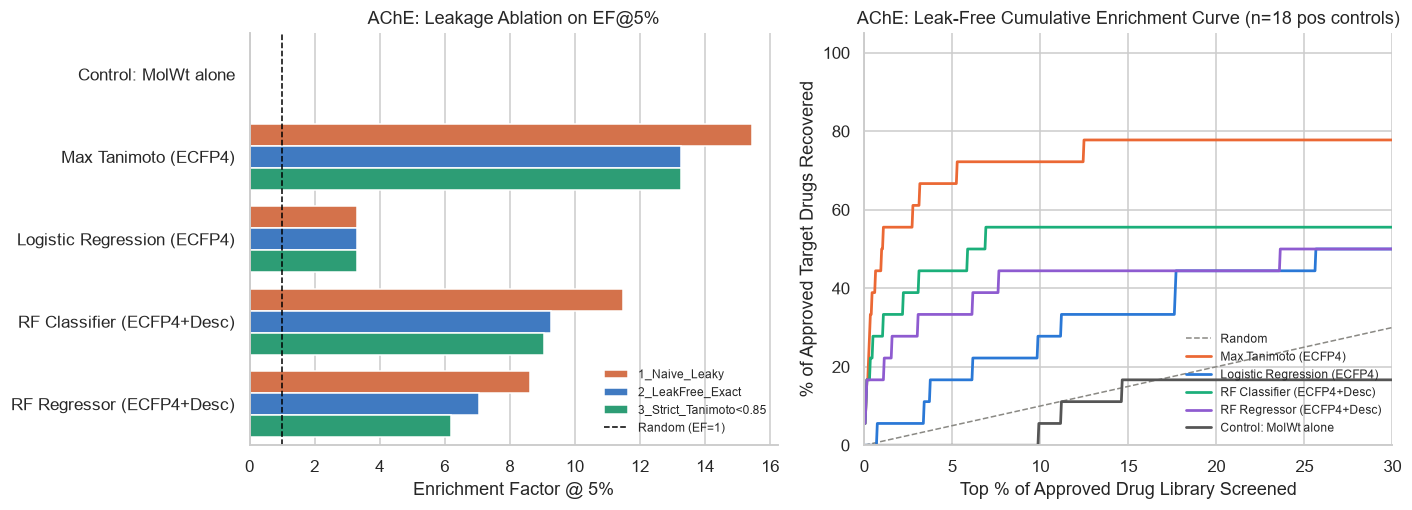


=== Top 15 Positive Controls (Sorted by Leak-Free Logistic Regression Rank) ===


,pref_name,molecule_chembl_id,rank_tanimoto,rank_lr_clf,rank_rf_reg,AD_max_tanimoto
2022,BENZGALANTAMINE,CHEMBL5095056,9,15,479,0.679
160,PHYSOSTIGMINE,CHEMBL94,3,69,3,0.784
162,DONEPEZIL,CHEMBL502,2,76,2,0.849
161,TACRINE,CHEMBL95,1,125,23,0.966
344,GALANTAMINE,CHEMBL659,5,200,700,0.755
204,NEOSTIGMINE,CHEMBL278020,22,227,155,0.550
1484,HEXAFLUORENIUM BROMIDE,CHEMBL1200933,802,358,32,0.271
468,PYRIDOSTIGMINE BROMIDE,CHEMBL812,56,359,1056,0.452
1389,DEMECARIUM BROMIDE,CHEMBL1200514,63,520,125,0.439
1328,DISTIGMINE BROMIDE,CHEMBL1098285,107,750,62,0.397



=== Top 10 Non-Approved Repurposing Hypotheses (Leak-Free Logistic Regression) ===


,pref_name,molecule_chembl_id,first_approval,rank_tanimoto,rank_lr_clf,rank_rf_reg,AD_max_tanimoto
1784,SONIDEGIB,CHEMBL2105737,2015.0,457,1,151,0.309
1971,BRILLIANT BLUE G,CHEMBL4173394,2019.0,1210,2,127,0.236
1653,TRELAGLIPTIN,CHEMBL1650443,NaN,1016,3,10,0.250
881,DARUNAVIR,CHEMBL1323,2006.0,1069,4,77,0.247
1140,HYDROCORTISONE CYPIONATE,CHEMBL1549,1955.0,1276,5,307,0.230
1419,ETOPOSIDE PHOSPHATE,CHEMBL1200645,1996.0,695,6,682,0.282
1721,CARIPRAZINE HYDROCHLORIDE,CHEMBL2024517,2015.0,125,7,19,0.387
905,RAMATROBAN,CHEMBL361812,2000.0,724,8,53,0.280
1340,AFATINIB,CHEMBL1173655,2013.0,1016,9,352,0.250
210,LAPATINIB,CHEMBL554,2007.0,1065,10,94,0.248


Saved full ranked approved library to data/processed/.


In [4]:
# Compute Applicability Domain (max Tanimoto to leak-free training actives)
app_bv = ecfp4_bitvects(approved_df["canonical_smiles"])
clean_act_bv = ecfp4_bitvects([s for s, y in zip(df_clf_clean.index, df_clf_clean["y"]) if y == 1])
approved_df["AD_max_tanimoto"] = max_tanimoto_similarity(app_bv, clean_act_bv)

# Attach leak-free average scores
for mname, sc in scores_clean.items():
    safe_col = "score_" + mname.lower().replace(" ", "_").replace("(", "").replace(")", "").replace(":", "").replace("+", "_")
    approved_df[safe_col] = sc

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Panel A: Leakage ablation on EF@5%
plot_methods = [
    "Max Tanimoto (ECFP4)",
    "Logistic Regression (ECFP4)",
    "RF Classifier (ECFP4+Desc)",
    "RF Regressor (ECFP4+Desc)",
    "Control: MolWt alone",
]
sub_ab = all_rank_res[all_rank_res["method"].isin(plot_methods)]
sns.barplot(data=sub_ab, y="method", x="EF@5%_mean", hue="leakage_tier", ax=axes[0], palette=["#eb6834", "#2a78d6", "#1baf7a"])
axes[0].axvline(1.0, color="black", ls="--", lw=1.0, label="Random (EF=1)")
axes[0].set(title=f"{TARGET}: Leakage Ablation on EF@5%", xlabel="Enrichment Factor @ 5%", ylabel="")
axes[0].legend(frameon=False, fontsize=8, loc="lower right")

# Panel B: Enrichment curves (Leak-Free Exact)
is_pos = approved_df["is_positive_control"].to_numpy(dtype=int)
n_tot = len(is_pos)
n_pos = is_pos.sum()
frac_x = np.arange(1, n_tot + 1) / n_tot * 100.0
axes[1].plot([0, 100], [0, 100], color="#8a8984", ls="--", lw=1.0, label="Random")

curve_styles = [
    ("Max Tanimoto (ECFP4)", "#eb6834"),
    ("Logistic Regression (ECFP4)", "#2a78d6"),
    ("RF Classifier (ECFP4+Desc)", "#1baf7a"),
    ("RF Regressor (ECFP4+Desc)", "#8e5bd0"),
    ("Control: MolWt alone", "#555555"),
]
for mname, col in curve_styles:
    order = np.argsort(-scores_clean[mname], kind="stable")
    cum_rec = np.cumsum(is_pos[order]) / n_pos * 100.0
    axes[1].plot(frac_x, cum_rec, color=col, lw=1.8, label=mname)

axes[1].set(
    title=f"{TARGET}: Leak-Free Cumulative Enrichment Curve (n={n_pos} pos controls)",
    xlabel="Top % of Approved Drug Library Screened",
    ylabel="% of Approved Target Drugs Recovered",
    xlim=(0, 30),
    ylim=(0, 105),
)
axes[1].legend(frameon=False, fontsize=8, loc="lower right")

plt.tight_layout()
fig.savefig(FIG_DIR / f"{TARGET_LOW}_checkpoint1_baselines.png", dpi=150, bbox_inches="tight")
plt.show()

# Show positive-control ranks & top 10 non-approved repurposing candidates under Logistic Regression (ECFP4) and RF Regressor (ECFP4+Desc)
approved_df["rank_lr_clf"] = approved_df["score_logistic_regression_ecfp4"].rank(ascending=False, method="min").astype(int)
approved_df["rank_rf_reg"] = approved_df["score_rf_regressor_ecfp4_desc"].rank(ascending=False, method="min").astype(int)
approved_df["rank_tanimoto"] = approved_df["score_max_tanimoto_ecfp4"].rank(ascending=False, method="min").astype(int)

print("\n=== Top 15 Positive Controls (Sorted by Leak-Free Logistic Regression Rank) ===")
pos_view = approved_df[approved_df["is_positive_control"] == 1].sort_values("rank_lr_clf")
display(pos_view[["pref_name", "molecule_chembl_id", "rank_tanimoto", "rank_lr_clf", "rank_rf_reg", "AD_max_tanimoto"]].head(15).round(3))

print("\n=== Top 10 Non-Approved Repurposing Hypotheses (Leak-Free Logistic Regression) ===")
cand_view = approved_df[approved_df["is_positive_control"] == 0].sort_values("rank_lr_clf")
display(cand_view[["pref_name", "molecule_chembl_id", "first_approval", "rank_tanimoto", "rank_lr_clf", "rank_rf_reg", "AD_max_tanimoto"]].head(10).round(3))

approved_df.to_csv(PROC_DIR / f"{TARGET_LOW}_approved_ranked_checkpoint1.csv", index=False)
print("Saved full ranked approved library to data/processed/.")
